<a href="https://colab.research.google.com/github/1824034QM/1824034QM/blob/main/Unit2(b).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---Energy Comparison---
State n=1: Numerical E= 0.9633 | Analytical E= 0.9663
State n=2: Numerical E= 3.8381 | Analytical E= 3.8507
State n=3: Numerical E= 8.5715 | Analytical E= 8.6002


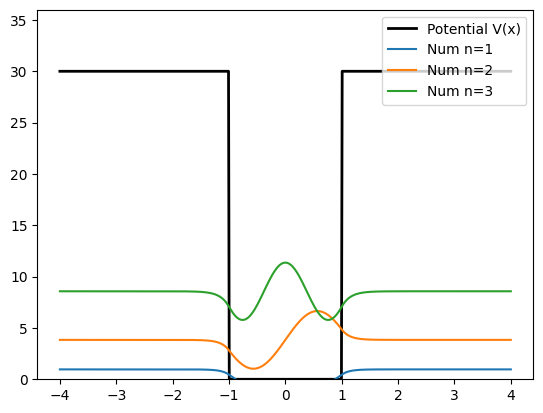

In [1]:


import numpy as np
import matplotlib.pyplot as plt

V0, a = 30, 1
L = 4
N = 600

x = np.linspace(-L, L, N)
dx = x[1]-x[0]

main_diag = 2*np.ones(N)
off_diag = -1*np.ones(N-1)

T = (1/(2*dx**2))*(np.diag(main_diag)+np.diag(off_diag,1)+np.diag(off_diag,-1))

V_array = np.where((x >= -a) & (x <= a), 0, V0)
V_matrix = np.diag(V_array)

H = T + V_matrix

energies, wavefunctions = np.linalg.eigh(H)

E_scan = np.linspace(0.1, V0-0.1, 100000)
k, alpha = np.sqrt(2*E_scan), np.sqrt(2*(V0-E_scan))

even_eq = alpha*np.cos(k*a)-k*np.sin(k*a)
odd_eq = alpha*np.sin(k*a)+k*np.cos(k*a)

E_ana = []

for eq in (even_eq, odd_eq):
    E_ana.extend(E_scan[np.where(np.diff(np.sign(eq)))[0]])

E_ana.sort()

plt.plot(x, V_array, 'k-', linewidth=2, label='Potential V(x)')
print('---Energy Comparison---')

for n in range(3):
    print(f'State n={n+1}: Numerical E= {energies[n]:.4f} | Analytical E= {E_ana[n]:.4f}')

    psi = wavefunctions[:, n]
    psi /= np.sqrt(np.sum(psi**2)*dx)

    plt.plot(x, energies[n]+3*psi, label=f'Num n={n+1}')

plt.ylim(0, V0*1.2)
plt.legend(loc='upper right')
plt.show()